# Étape 3 & 4: Brain Tumor Classification with Transfer Learning (MobileNetV2)
- Load preprocessed datasets (Train, Val, Test).
- Build MobileNetV2 with a custom 4-class head.
- Phase 1: Train top layers (frozen base).
- Phase 2: Fine-tune top layers with low learning rate.
- Overfitting prevention: Dropout, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint.

## 1. Setup, Imports & Dataset Loading

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt 
import tensorflow as tf


DATA_DIR = Path('../data')
  
IMG_SIZE = (224, 224)
  
BATCH_SIZE = 32
  
AUTOTUNE = tf.data.AUTOTUNE

IMG_SIZE = (224, 224)

BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / 'Train' ,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / 'Val' ,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / 'Test' ,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False)

class_names = train_ds.class_names

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print(class_names)

I0000 00:00:1792938671.491319    8210 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792938671.496814    8210 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792938671.937887    8210 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792938674.138156    8210 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Found 3840 files belonging to 4 classes.
Found 984 files belonging to 4 classes.
Found 425 files belonging to 4 classes.


E0000 00:00:1792938676.368803    8210 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


## 2. Building MobileNetV2 Transfer Learning Architecture
- Load pretrained MobileNetV2 backbone (ImageNet weights, include_top=False).
- Freeze pretrained base layers (Phase 1: Feature Extraction).
- Attach custom head: GlobalAveragePooling2D, Dense (L2), Dropout(0.3), Softmax(4).

In [2]:
# load pretrained base model with imagenet weights
base_model = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

# freeze the base model layers
base_model.trainable = False

# input layer
inputs = tf.keras.Input(shape=(224, 224, 3))

# scale pixel values
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# pass through frozen base
x = base_model(x, training=False)

# pool features to a vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# dense layer with weight regularization
x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)

# randomly drop connections to reduce overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# final prediction layer for classes
outputs = tf.keras.layers.Dense(4, activation='softmax')(x)

# combine inputs and outputs into final model
model = tf.keras.Model(inputs, outputs)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 3. Training Callbacks & Model Compilation (Phase 1)
- EarlyStopping: stops training when val_loss stagnates for 5 epochs.
- ModelCheckpoint: saves the best model to models/best_mobilenet_phase1.keras.
- ReduceLROnPlateau: cuts learning rate when progress slows down.
- Compile model: Adam optimizer (lr=0.001) with categorical crossentropy.

In [3]:
# create directory for saved models
os.makedirs('../models', exist_ok=True)

# list of training callbacks
callbacks = [
    # stop training when validation loss stops improving
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    # save the best model weights
    tf.keras.callbacks.ModelCheckpoint(
        filepath='../models/best_mobilenet_phase1.keras',
        monitor='val_loss',
        save_best_only=True
    ),
    # reduce learning rate when progress slows down
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-6
    )
]

# compile model with adam optimizer and loss function
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("model compiled with callbacks ready")


model compiled with callbacks ready


## 4. Phase 1 Training: Feature Extraction (Frozen Base)
- Train the custom classification head for 15 epochs.
- Base model remains frozen.
- Callbacks monitor val_loss, save the best weights, and apply early stopping.

In [4]:
EPOCHS = 15


history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15


/home/emad/Desktop/AI projects/IRM detection/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


120/120 ━━━━━━━━━━━━━━━━━━━━ 97s 756ms/step - accuracy: 0.8180 - loss: 0.6784 - val_accuracy: 0.8862 - val_loss: 0.5012 - learning_rate: 0.0010
Epoch 2/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 77s 640ms/step - accuracy: 0.9039 - loss: 0.4186 - val_accuracy: 0.8760 - val_loss: 0.4743 - learning_rate: 0.0010
Epoch 3/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 78s 651ms/step - accuracy: 0.9237 - loss: 0.3434 - val_accuracy: 0.9116 - val_loss: 0.3731 - learning_rate: 0.0010
Epoch 4/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 78s 650ms/step - accuracy: 0.9565 - loss: 0.2585 - val_accuracy: 0.9309 - val_loss: 0.3180 - learning_rate: 0.0010
Epoch 5/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 74s 613ms/step - accuracy: 0.9680 - loss: 0.2270 - val_accuracy: 0.9411 - val_loss: 0.2967 - learning_rate: 0.0010
Epoch 6/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 72s 597ms/step - accuracy: 0.9755 - loss: 0.1991 - val_accuracy: 0.9543 - val_loss: 0.2707 - learning_rate: 0.0010
Epoch 7/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 71s 595ms/step - accuracy: 0.9841 - loss:

## 5. Learning Curves Analysis (Phase 1)
- Plot training vs validation accuracy.
- Plot training vs validation loss.
- Inspect curves to verify healthy convergence without severe overfitting.

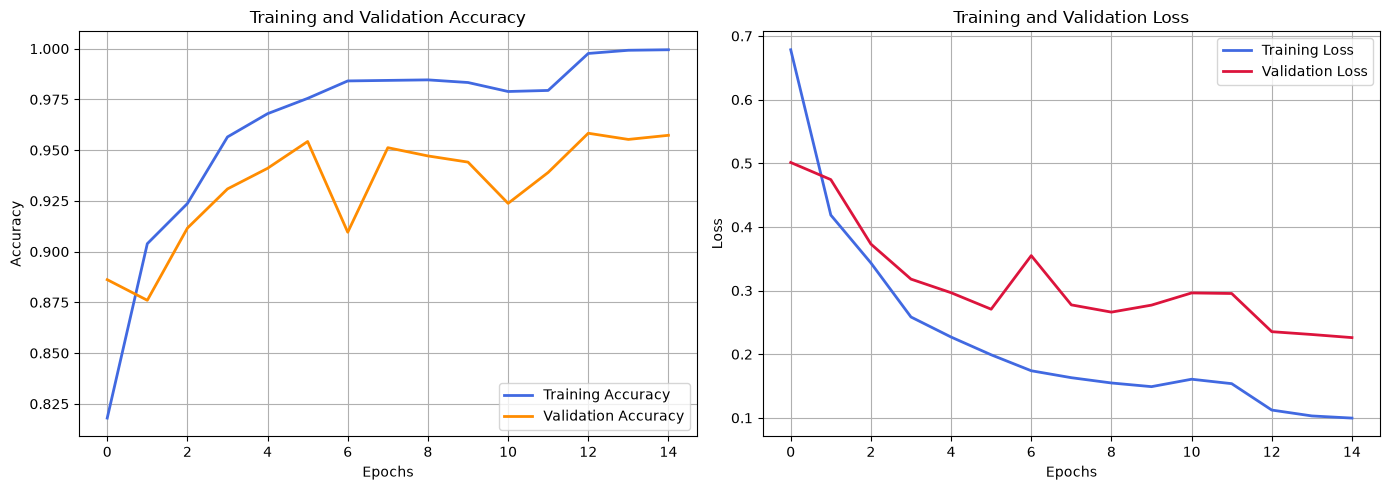

In [5]:
# extract training metrics
acc = history_phase1.history['accuracy']
val_acc = history_phase1.history['val_accuracy']
loss = history_phase1.history['loss']
val_loss = history_phase1.history['val_loss']

# range of epochs for x axis
epochs_range = range(len(acc))

# create side by side figure
plt.figure(figsize=(14, 5))

# accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='royalblue', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='darkorange', linewidth=2)
plt.title('Training and Validation Accuracy', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='royalblue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='crimson', linewidth=2)
plt.title('Training and Validation Loss', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()


## 6. Phase 2: Fine-Tuning (Unfreezing Top Layers)
- Unfreeze the base model, but keep all layers frozen except the last 30 layers.
- Recompile with a very low learning rate (1e-5).
- Update checkpoint to save models/best_mobilenet_fine_tuned.keras.

In [6]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='categorical_crossentropy', 
                metrics=['accuracy'])

callbacks_fine_tune = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath='../models/best_mobilenet_fine_tuned.keras',
        monitor='val_loss',
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 1,690,884 (6.45 MB)

 Non-trainable params: 731,584 (2.79 MB)

## 7. Phase 2 Training: Fine-Tuning Execution
- Train the unfrozen layers for 10 additional epochs.
- Uses low learning rate (1e-5) to adapt deep filters without destroying weights.
- Saves best weights to models/best_mobilenet_fine_tuned.keras.

In [7]:
EPOCHS_FINE_TUNE = 10

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=callbacks_fine_tune
)

Epoch 1/10


/home/emad/Desktop/AI projects/IRM detection/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 682ms/step - accuracy: 0.9974 - loss: 0.1002 - val_accuracy: 0.9634 - val_loss: 0.2420 - learning_rate: 1.0000e-05
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 692ms/step - accuracy: 0.9990 - loss: 0.0925 - val_accuracy: 0.9533 - val_loss: 0.2335 - learning_rate: 1.0000e-05
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 684ms/step - accuracy: 1.0000 - loss: 0.0862 - val_accuracy: 0.9614 - val_loss: 0.2283 - learning_rate: 1.0000e-05
Epoch 4/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 693ms/step - accuracy: 1.0000 - loss: 0.0835 - val_accuracy: 0.9583 - val_loss: 0.2323 - learning_rate: 1.0000e-05
Epoch 5/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 681ms/step - accuracy: 1.0000 - loss: 0.0824 - val_accuracy: 0.9583 - val_loss: 0.2333 - learning_rate: 1.0000e-05
Epoch 6/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 685ms/step - accuracy: 1.0000 - loss: 0.0816 - val_accuracy: 0.9604 - val_loss: 0.2271 - learning_rate: 1.0000e-05
Epoch 7/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 81s 678ms/step - 

## 8. Configuration Comparison: Phase 1 vs Phase 2 Curves
- Combine training history from Phase 1 and Phase 2.
- Plot continuous accuracy and loss trajectories.
- Dotted vertical line marks the transition to fine-tuning.


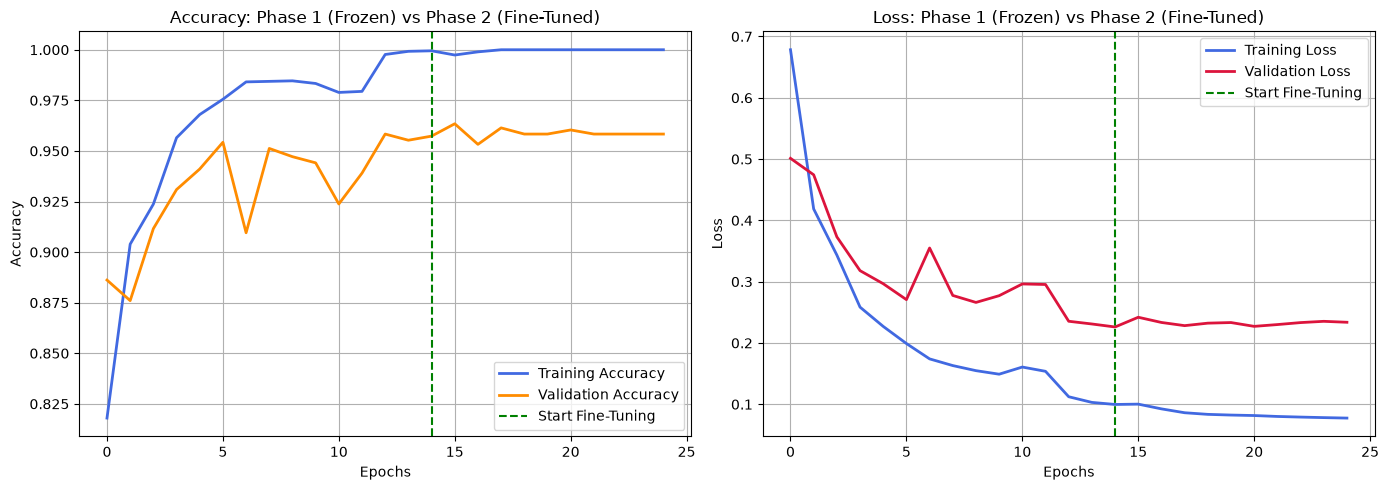

In [8]:
# combine metrics from both training configurations
acc_total = history_phase1.history['accuracy'] + history_phase2.history['accuracy']
val_acc_total = history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy']
loss_total = history_phase1.history['loss'] + history_phase2.history['loss']
val_loss_total = history_phase1.history['val_loss'] + history_phase2.history['val_loss']

# split point between frozen base and fine tuning
split_epoch = len(history_phase1.history['loss']) - 1

# create side by side comparison plots
plt.figure(figsize=(14, 5))

# accuracy trajectory plot
plt.subplot(1, 2, 1)
plt.plot(acc_total, label='Training Accuracy', color='royalblue', linewidth=2)
plt.plot(val_acc_total, label='Validation Accuracy', color='darkorange', linewidth=2)
plt.axvline(x=split_epoch, color='green', linestyle='--', label='Start Fine-Tuning')
plt.title('Accuracy: Phase 1 (Frozen) vs Phase 2 (Fine-Tuned)', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# loss trajectory plot
plt.subplot(1, 2, 2)
plt.plot(loss_total, label='Training Loss', color='royalblue', linewidth=2)
plt.plot(val_loss_total, label='Validation Loss', color='crimson', linewidth=2)
plt.axvline(x=split_epoch, color='green', linestyle='--', label='Start Fine-Tuning')
plt.title('Loss: Phase 1 (Frozen) vs Phase 2 (Fine-Tuned)', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()


## 9. Final Model Evaluation on the Test Set (Étape 6)
- Load best fine-tuned model checkpoint from disk.
- Compute Accuracy, Precision, Recall, and F1-score across all 4 classes.
- Plot the Confusion Matrix heatmap to analyze misclassifications.


14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 494ms/step - accuracy: 0.9435 - loss: 0.2951
test accuracy: 0.9435
test loss: 0.2951
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 494ms/step

classification report:
              precision    recall  f1-score   support

      Glioma       0.97      0.95      0.96       103
  Meningioma       0.91      0.91      0.91       130
    No Tumor       0.93      0.97      0.95        64
   Pituitary       0.96      0.96      0.96       128

    accuracy                           0.94       425
   macro avg       0.94      0.95      0.94       425
weighted avg       0.94      0.94      0.94       425



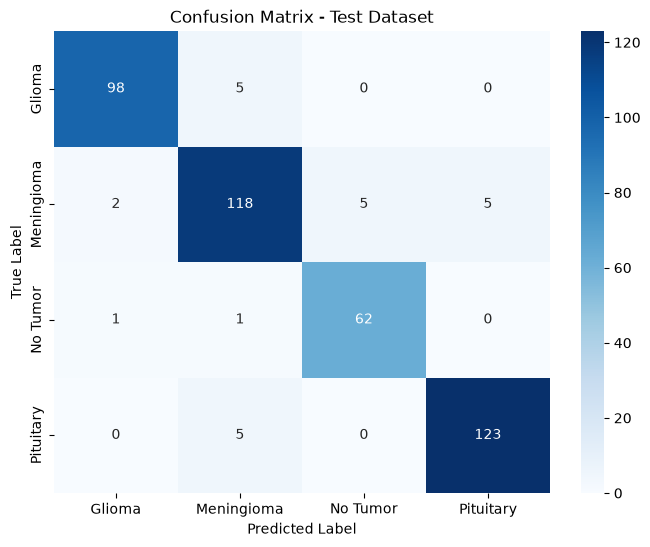

In [9]:
# import evaluation tools
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# load the best saved model from disk
best_model = tf.keras.models.load_model('../models/best_mobilenet_fine_tuned.keras')

# evaluate directly on untouched test dataset
test_loss, test_accuracy = best_model.evaluate(test_ds)
print(f"test accuracy: {test_accuracy:.4f}")
print(f"test loss: {test_loss:.4f}")

# get predictions and true labels
predictions_prob = best_model.predict(test_ds)
predictions = np.argmax(predictions_prob, axis=1)
true_labels = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])

# print precision recall and fscore report
print("\nclassification report:")
print(classification_report(true_labels, predictions, target_names=class_names))

# compute confusion matrix
cm = confusion_matrix(true_labels, predictions)

# plot confusion matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Test Dataset', fontsize=12)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()
